# Transfer Learning

In [1]:
import numpy as np
import tensorflow as tf
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential, load_model, Model
from tensorflow.keras.layers import Dense, Dropout, Flatten, Input
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

In [2]:
digits = load_digits()
X = digits.images.astype('float32')
y = digits.target
X.shape, y.shape

((1797, 8, 8), (1797,))

In [4]:
X[0]

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
       [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
       [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
       [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
       [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
       [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
       [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
       [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]], dtype=float32)

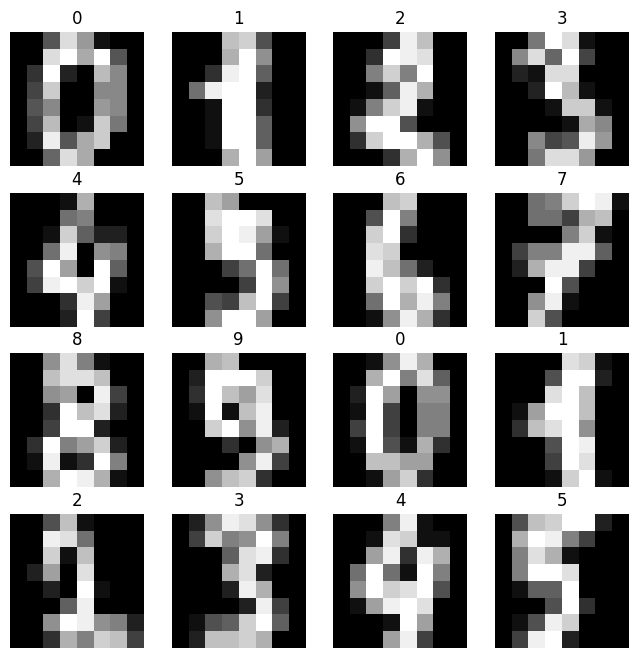

In [3]:
plt.figure(figsize=(8, 8))
for i in range(16):
    plt.subplot(4, 4, i+1)
    plt.imshow(X[i], cmap='gray')
    plt.axis('off')
    plt.title(y[i])
plt.show()

In [5]:
#  Normalization
X = X / 16
X[0]

array([[0.    , 0.    , 0.3125, 0.8125, 0.5625, 0.0625, 0.    , 0.    ],
       [0.    , 0.    , 0.8125, 0.9375, 0.625 , 0.9375, 0.3125, 0.    ],
       [0.    , 0.1875, 0.9375, 0.125 , 0.    , 0.6875, 0.5   , 0.    ],
       [0.    , 0.25  , 0.75  , 0.    , 0.    , 0.5   , 0.5   , 0.    ],
       [0.    , 0.3125, 0.5   , 0.    , 0.    , 0.5625, 0.5   , 0.    ],
       [0.    , 0.25  , 0.6875, 0.    , 0.0625, 0.75  , 0.4375, 0.    ],
       [0.    , 0.125 , 0.875 , 0.3125, 0.625 , 0.75  , 0.    , 0.    ],
       [0.    , 0.    , 0.375 , 0.8125, 0.625 , 0.    , 0.    , 0.    ]],
      dtype=float32)

In [6]:
# Split to train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1437, 8, 8), (360, 8, 8), (1437,), (360,))

In [7]:
y_train

array([6, 0, 0, ..., 2, 7, 1])

In [8]:
num_classes = len(np.unique(y))
num_classes

10

## Make the problem a binary classification problem

In [9]:
y_train_binary = (y_train % 2).astype(np.float32)
y_test_binary = (y_test % 2).astype(np.float32)
y_test_binary

array([0., 1., 1., 1., 0., 1., 1., 0., 1., 0., 1., 1., 0., 0., 0., 0., 1.,
       1., 0., 0., 0., 1., 1., 1., 1., 0., 1., 1., 0., 1., 0., 1., 1., 0.,
       0., 0., 1., 0., 1., 0., 0., 1., 1., 1., 0., 1., 1., 0., 0., 1., 1.,
       1., 1., 1., 0., 0., 1., 0., 0., 1., 0., 0., 1., 0., 0., 1., 1., 0.,
       1., 1., 1., 1., 1., 0., 1., 0., 0., 1., 1., 1., 1., 0., 0., 1., 0.,
       0., 0., 0., 0., 1., 1., 0., 0., 1., 1., 0., 1., 0., 0., 0., 0., 1.,
       1., 1., 1., 1., 1., 1., 0., 0., 1., 1., 0., 0., 1., 1., 0., 1., 0.,
       1., 0., 0., 1., 0., 0., 1., 0., 1., 1., 0., 1., 1., 1., 1., 0., 0.,
       0., 0., 0., 0., 0., 1., 0., 0., 1., 1., 0., 1., 0., 1., 1., 0., 0.,
       0., 0., 0., 1., 1., 1., 1., 1., 0., 1., 0., 0., 1., 1., 0., 1., 1.,
       1., 0., 0., 0., 1., 1., 1., 1., 0., 0., 1., 1., 0., 0., 1., 0., 0.,
       1., 0., 1., 1., 0., 1., 1., 0., 0., 1., 0., 0., 0., 1., 1., 1., 1.,
       0., 1., 0., 0., 1., 1., 0., 0., 1., 0., 1., 0., 0., 0., 0., 1., 0.,
       1., 0., 0., 0., 1.

## Transfer Learning

In [10]:
base_model = load_model('trained_digits_model.keras')
base_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,912 (105.13 KB)

 Trainable params: 8,970 (35.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 17,942 (70.09 KB)

In [13]:
# Rebuild with frozen base model
inpt = Input(shape=X.shape[1:])
x = inpt

for layer in base_model.layers[:-1]:
  layer.trainable = False
  x = layer(x)

model = Model(inpt, x)


In [14]:
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 8, 8)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,320 (32.50 KB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 8,320 (32.50 KB)

In [15]:
# New binary classification header
out = Dense(1, activation='sigmoid', name="new_binary_head")(x)

In [16]:
transferLearnedModel = Model(inpt, out)
transferLearnedModel.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 8, 8)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ new_binary_head (Dense)         │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,385 (32.75 KB)

 Trainable params: 65 (260.00 B)

 Non-trainable params: 8,320 (32.50 KB)

In [17]:
transferLearnedModel.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [19]:
history = transferLearnedModel.fit(X_train,
                                    y_train_binary,
                                    epochs=20,
                                    validation_split=0.2,
                                    verbose=2)

Epoch 1/20
36/36 - 1s - 22ms/step - accuracy: 0.4804 - loss: 1.1415 - val_accuracy: 0.4618 - val_loss: 0.9212
Epoch 2/20
36/36 - 0s - 3ms/step - accuracy: 0.5144 - loss: 0.7468 - val_accuracy: 0.5174 - val_loss: 0.6675
Epoch 3/20
36/36 - 0s - 3ms/step - accuracy: 0.6484 - loss: 0.5840 - val_accuracy: 0.7431 - val_loss: 0.5260
Epoch 4/20
36/36 - 0s - 3ms/step - accuracy: 0.7885 - loss: 0.4942 - val_accuracy: 0.8368 - val_loss: 0.4442
Epoch 5/20
36/36 - 0s - 3ms/step - accuracy: 0.8251 - loss: 0.4397 - val_accuracy: 0.8576 - val_loss: 0.3956
Epoch 6/20
36/36 - 0s - 3ms/step - accuracy: 0.8407 - loss: 0.4042 - val_accuracy: 0.8889 - val_loss: 0.3625
Epoch 7/20
36/36 - 0s - 3ms/step - accuracy: 0.8503 - loss: 0.3782 - val_accuracy: 0.8889 - val_loss: 0.3394
Epoch 8/20
36/36 - 0s - 4ms/step - accuracy: 0.8634 - loss: 0.3576 - val_accuracy: 0.9028 - val_loss: 0.3208
Epoch 9/20
36/36 - 0s - 3ms/step - accuracy: 0.8660 - loss: 0.3412 - val_accuracy: 0.8993 - val_loss: 0.3066
Epoch 10/20
36/36 

In [20]:
transferLearnedModel.evaluate(X_test, y_test_binary)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9028 - loss: 0.2598  


[0.25983813405036926, 0.9027777910232544]

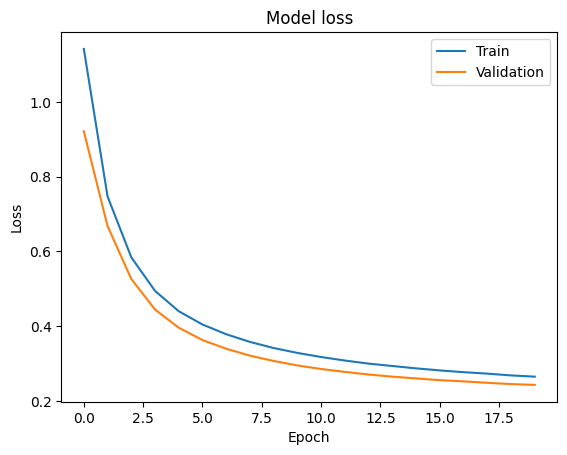

In [21]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.show()

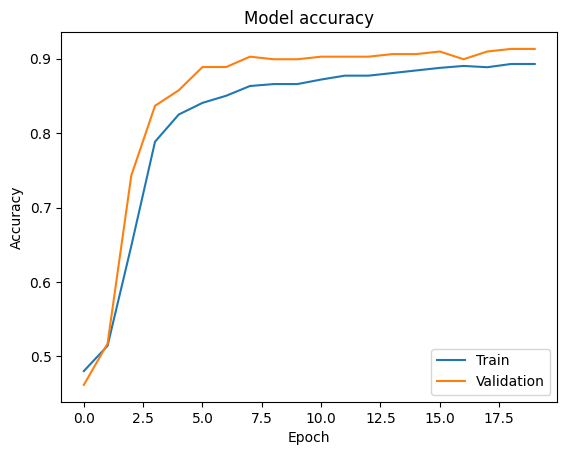

In [22]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.show()